In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from sklearn.metrics import auc
import random

In [2]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
dhs = pd.read_table('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38.txt.gz', header=None).T
dhs.shape

(733, 3591898)

In [3]:
#Loading biosample embeddings
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
decomp_Basis = np.load(fn)

In [4]:
#Loading DHS embeddings
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
decomp_Mixture = np.load(fn)

In [5]:
dhs_array = dhs.to_numpy()

In [6]:
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
df = pd.read_csv(tsv_file, delimiter="\t")
biosample_df = df[['library order', 'Biosample name']]

In [7]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [8]:
#reordering dataframe to match order of presence/absence matrix and DHS metadata dataframe
#first bigwig file
# GM06990_signal = pd.read_table('/home/ctrader/lightfm_data/out_ENCFF691MRD.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'mean'])

#second bigwig file
GM06990_signal = pd.read_table('/home/ctrader/lightfm_data/out_ENCFF962FBP.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'mean'])

GM06990_signal[['name']] = GM06990_signal[['name']].astype(str)
GM06990_signal = GM06990_signal.set_index('name')
id_order = DHS_metadata['identifier'].to_list()
GM06990_signal = GM06990_signal.reindex(id_order)
GM06990_signal = GM06990_signal.reset_index()

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (0) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [9]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['grey', 'darkorchid', 'deepskyblue', 'slateblue', 'orange', 'slategrey', 'gold', 'royalblue', 'green', 'saddlebrown', 'chocolate', 'olivedrab', 'seagreen', 'darkolivegreen', 'red', 'darkblue']

In [10]:
#Top 15 biosamples of each component
top_biosamples = pd.read_table('/home/ctrader/lightfm_data/top15NMFBasisLoadings.txt')

In [44]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['grey', 'darkorchid', 'deepskyblue', 'slateblue', 'orange', 'slategrey', 'gold', 'royalblue', 'green', 'saddlebrown', 'chocolate', 'olivedrab', 'seagreen', 'darkolivegreen', 'red', 'darkblue']
biosamples = []
biosample_names = []
for comp in comps:
    biosamples.append(list(df[df['Altius Biosample ID'] == list(top_biosamples[comp])[0]].index)[0])
    biosample_names.append(list(df[df['Altius Biosample ID'] == list(top_biosamples[comp])[0]]['Biosample name'])[0])
    biosamples.append(list(df[df['Altius Biosample ID'] == list(top_biosamples[comp])[-1]].index)[0])
    biosample_names.append(list(df[df['Altius Biosample ID'] == list(top_biosamples[comp])[-1]]['Biosample name'])[0])

In [16]:
n_biosamples, n_biosample_e = decomp_Basis.shape
n_DHS_e, n_DHSs = decomp_Mixture.shape
print(n_biosamples, n_DHSs)

733 3591898


In [17]:
k_vals = list(range(1, 1000))
k_vals.extend(list(np.arange(1000, n_DHSs, 10000)))
print(len(k_vals))

1359


In [19]:
top_biosample_precision = []
top_biosample_recall = []
for sample in biosamples:
    l = []
    l.append(sample)
    rec_info = sample_recommendation(l, GM06990_signal, print_num=0)
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(rec_info[0], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    top_biosample_precision.append(all_comps_precision)
    top_biosample_recall.append(all_comps_recall)

Biosample: 262 (262)
   Number of Known DHSs: 45431

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal
Biosample: 227 (227)
   Number of Known DHSs: 47071

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal
Biosample: 444 (444)
   Number of Known DHSs: 100575

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal
Biosample: 125 (125)
   Number of Known DHSs: 89913

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal
Biosample: 44 (44)
   Number of Known DHSs: 314868

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Si

In [22]:
pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_top1_top15_biosamples_each_comp_precision.pickle', 'wb')
pickle.dump(top_biosample_precision, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_top1_top15_biosamples_each_comp_recall.pickle', 'wb')
pickle.dump(top_biosample_recall, pickle_out)
pickle_out.close()

In [2]:
pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_top1_top15_biosamples_each_comp_precision.pickle', 'rb')
top_biosample_precision=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_top1_top15_biosamples_each_comp_recall.pickle', 'rb')
top_biosample_recall=pickle.load(pickle_in)

In [28]:
len(top_biosample_precision[0][0])

1359

In [3]:
total_auc = []
for i in range(len(top_biosample_precision)):
    comp_auc = []
    for j in range(len(top_biosample_precision[i])):
        comp_auc.append(auc(top_biosample_recall[i][j], top_biosample_precision[i][j]))
    total_auc.append(comp_auc)

In [36]:
len(total_auc)

32

Text(0.465, 1.03, 'Component PR Curve AUC Values for Top Biosamples of Each Component with NMF Recommendations')

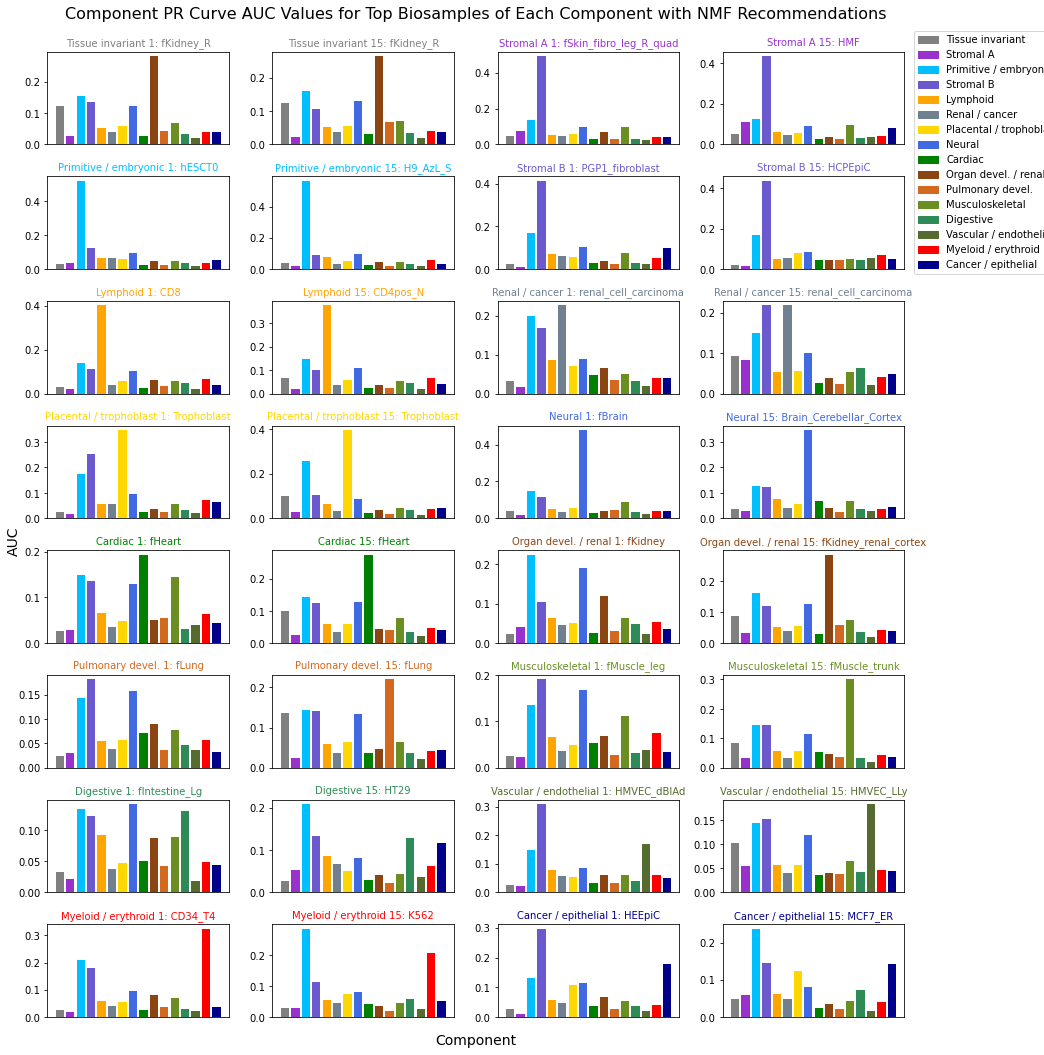

In [26]:
fig, axes = plt.subplots(nrows=8, ncols=4, figsize=(14,14))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes, range(32)):
#     for i in range(len(comps)):
#         ax.plot(top_biosample_recall[ind][i], top_biosample_precision[ind][i], color=color[i])
    ax.bar(comps, total_auc[ind], color=color)
    if ind % 2 == 0:
        biosample_rank = '1'
    else:
        biosample_rank = '15'
    component = comps[ind // 2]
    ax.set_title(component + ' ' + biosample_rank + ': ' + biosample_names[ind], fontsize=10, color=color[ind//2])
    ax.set_xticks([])
    
fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()

handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, comps, loc = (0.875, 0.74))
# print(lines)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Component', ha='center', fontsize=14)
fig.text(0, 0.5, 'AUC', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Component PR Curve AUC Values for Top Biosamples of Each Component with NMF Recommendations', fontsize=16, x=0.465, y=1.03)

Text(0.465, 1.03, 'Component Precision-Recall Curves for Top Biosamples of Each Component with NMF Recommendations')

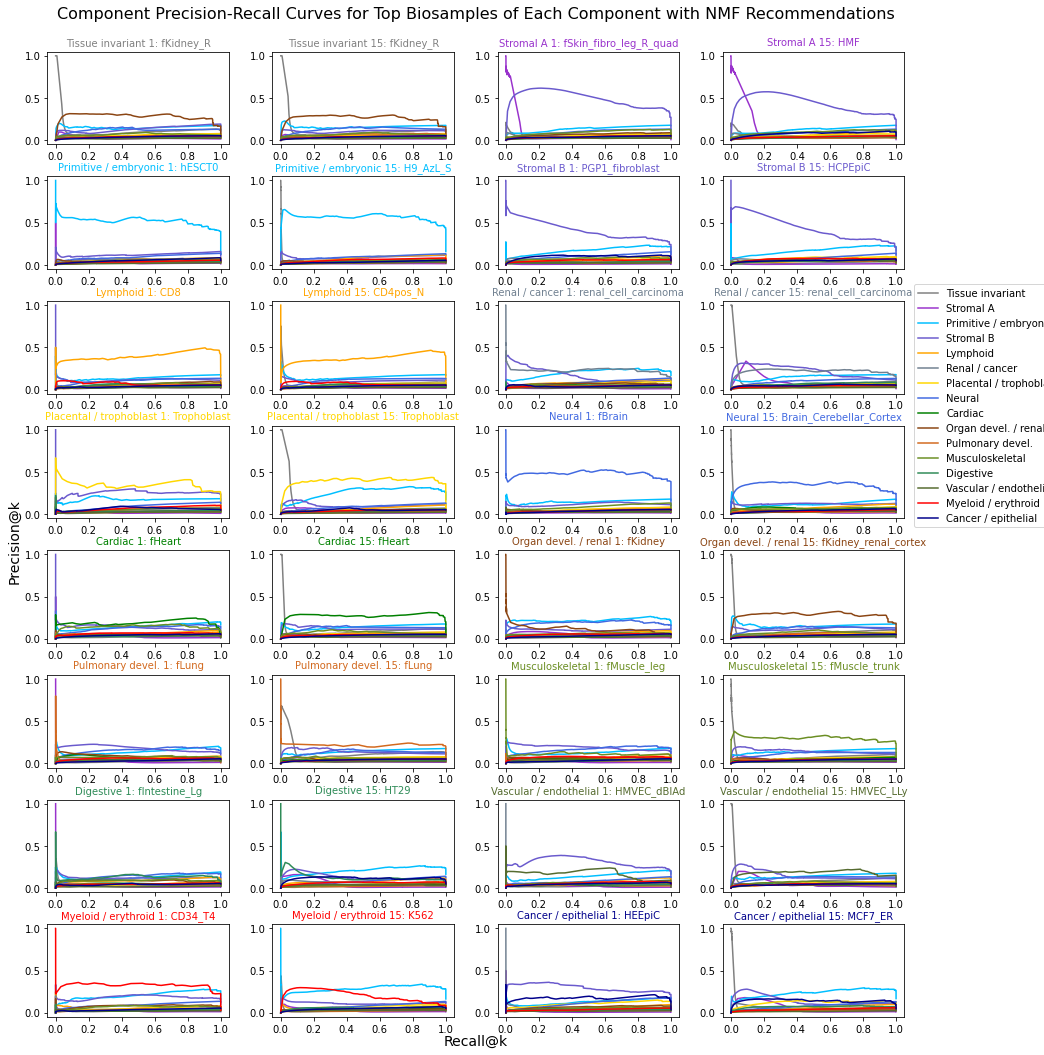

In [23]:
fig, axes = plt.subplots(nrows=8, ncols=4, figsize=(14,14))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes, range(32)):
    for i in range(len(comps)):
        ax.plot(top_biosample_recall[ind][i], top_biosample_precision[ind][i], color=color[i])
    if ind % 2 == 0:
        biosample_rank = '1'
    else:
        biosample_rank = '15'
    component = comps[ind // 2]
    ax.set_title(component + ' ' + biosample_rank + ': ' + biosample_names[ind], fontsize=10, color=color[ind//2])


fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()
fig.legend(comps, loc = (0.875, 0.5))
# print(lines)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Recall@k', ha='center', fontsize=14)
fig.text(0, 0.5, 'Precision@k', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Component Precision-Recall Curves for Top Biosamples of Each Component with NMF Recommendations', fontsize=16, x=0.465, y=1.03)

In [11]:
#function to recommend DHSs for a given biosample. Takes in the model, data, and a list of
#biosamples for DHSs to be recommend for. For each biosample, prints out known associated DHSs
#and a list of recommended DHSs. Function modeled after tutorial 3, 'Recommendation Systems
#- Learn Python for Data Science' on LightFM github. 

def sample_recommendation(biosamples, signal_data, print_num=3, biosample_e=decomp_Basis, DHS_e=decomp_Mixture): #, full_data=gd_coo
    
    #number of biosamples and DHSs in dataset
    n_biosamples, n_biosample_e = biosample_e.shape
    n_DHS_e, n_DHSs = DHS_e.shape
    return_list = []
    #generate DHS recommendations for each biosample
    for biosample_name in biosamples:
        if isinstance(biosample_name, str):
            biosample = list(biosample_df[biosample_df['Biosample name']==biosample_name]['library order'])[0] - 1
        else:
            biosample = biosample_name
        
        #DHSs known to relate to the biosample
        #indices
        known_positives = [i for i, dhs_pos in enumerate(list(dhs.T[biosample])) if dhs_pos == 1]
        
        #filter out known positives from what will be recommended
        not_known_ind = list(set(np.arange(n_DHSs)) - set(known_positives))
        
        nki_series = pd.Series(not_known_ind)
        
        #DHSs model predictions that relate to biosample
        filtered_scores = np.dot(decomp_Basis[biosample, :], decomp_Mixture[:, np.array(not_known_ind)])
        

        #rank from most related to least
        #not DHS indices
        filtered_top_DHSs = [np.argsort(-filtered_scores)][0]
        top_rec_DHSs = nki_series[filtered_top_DHSs]
        top_filtered_scores = filtered_scores[filtered_top_DHSs]
        
        metadata = DHS_metadata.reset_index()
        comp_ser = metadata['component']
        comp_rec = list(comp_ser[top_rec_DHSs])
        chrom_ser = metadata['seqname']
        chrom_rec = list(chrom_ser[top_rec_DHSs])
        start_ser = metadata['start']
        start_rec = list(start_ser[top_rec_DHSs])
        end_ser = metadata['end']
        end_rec = list(end_ser[top_rec_DHSs])
        numsamples_ser = metadata['numsamples']
        numsamples_rec = list(numsamples_ser[top_rec_DHSs])
        identifier_ser = metadata['identifier']
        identifier_rec = list(identifier_ser[top_rec_DHSs])
        
        #print results
        print('Biosample: %s (%s)' %(biosample_name, str(biosample)))
        print('   Number of Known DHSs: %s' %(len(known_positives)))
        print()
        print('   Recommended DHS Locations: ') 
        print('   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal')
        count = 0
        total_count = 0
        return_biosample = []
        return_biosample.append(comp_rec)
        return_biosample.append(chrom_rec)
        return_biosample.append(start_rec)
        return_biosample.append(end_rec)
        return_biosample.append(numsamples_rec)
        return_biosample.append(list(top_rec_DHSs))
        return_biosample.append(list(top_filtered_scores))
        return_list.append(return_biosample)
        
        
        dhs_ids = top_rec_DHSs.to_numpy()
        #dhs to the right of recommended dhs
        dhs_right = dhs_ids[:]+1
        #dhs to the left of recommended dhs
        dhs_left = dhs_ids[:]-1
        
        #removing dhss that are "neighbored" across chromosomes
        chrm_list = list(np.unique(list(DHS_metadata['seqname'])))
        rows_per_chrm = [0]
        for chrm in chrm_list:
            max_row = max(rows_per_chrm)
            rows, col = DHS_metadata[DHS_metadata['seqname']==chrm].shape
            rows_per_chrm.append(rows + max_row)
        rows_per_chrm = np.array(rows_per_chrm)
        
        dhs_right = np.delete(dhs_right, np.isin(dhs_right, rows_per_chrm))
        dhs_left = np.delete(dhs_left, np.isin(dhs_left, rows_per_chrm-1))
        
        #determining presence/absense of dhss to right and left of recommended dhs
        right = dhs_array[biosample, dhs_right] 
        left = dhs_array[biosample, dhs_left]
        
        #signal data
        sample_rec_dhs_signal, rec_dhs_signal, rec_identifier = signal_values(list(top_rec_DHSs), signal_data)
        sample_right_dhs_signal, right_dhs_signal, right_identifier = signal_values(list(dhs_right), signal_data)
        sample_left_dhs_signal, left_dhs_signal, left_identifier = signal_values(list(dhs_left), signal_data)
#         print(rec_identifier[:5])
#         print(identifier_rec[:5])
        
        
        for i in range(print_num):
#             print(identifier_rec[i])
#             print(rec_identifier[:5])
#             print(list(rec_identifier)[i])
            chrom = chrom_rec[i]
            start = start_rec[i]
            end = end_rec[i]
            component = comp_rec[i]
            num_samples = numsamples_rec[i]
            sample_rec_dhs_signal_i = round(list(sample_rec_dhs_signal)[i], 3)
            rec_dhs_signal_i = round(float(list(rec_dhs_signal)[i]), 3)
            dhs_id = list(top_rec_DHSs)[i]
            right_id = list(np.where(dhs_right == dhs_id+1))[0] #+1
            if list(right_id) and right[right_id]==1:
#                 print(int(right_id[0]))
                sample_right_dhs_signal_i = round(sample_right_dhs_signal[int(right_id[0])], 3)
                right_dhs_signal_i = round(right_dhs_signal[int(right_id[0])], 3)
                right_print = str(round(sample_right_dhs_signal_i, 3)) + '/' + str(round(right_dhs_signal_i, 3))
            else:
                right_print = 'N/A'
            
            left_id = list(np.where(dhs_left == dhs_id-1))[0]
            if list(left_id) and left[left_id]==1:
#                 print(int(left_id[0]))
                sample_left_dhs_signal_i = round(sample_left_dhs_signal[int(left_id[0])], 3)
                left_dhs_signal_i = round(left_dhs_signal[int(left_id[0])], 3)
                left_print = str(round(sample_left_dhs_signal_i, 3)) + '/' + str(round(left_dhs_signal_i, 3))
            else:
                left_print = 'N/A'
            
            
            print('      %s:%s-%s | %s | %s | %s/%s | %s | %s'
                  %(chrom, start, end, component, num_samples, sample_rec_dhs_signal_i, rec_dhs_signal_i,
                   left_print, right_print))

    return return_list

In [12]:
#Takes in recommended DHS indices and the signal data from a single biosample. Returns the average biosample signal
#across each recommended DHS and the average signal of all biosamples at each recommended DHS. 
def signal_values(dhs, signal_data):
    identifier_series = pd.Series(signal_data['name'])
    identifier = identifier_series[dhs]
    #Average biosample signal across each recommended DHS
    mean_signal_sample_series = pd.Series(signal_data['mean'])
    mean_signal_sample = mean_signal_sample_series[dhs]
    #Average signal of all biosamples at each recommended DHS
    mean_signal_DHS_series = pd.Series(DHS_metadata['mean_signal'])
    mean_signal_DHS = mean_signal_DHS_series[dhs]
    return list(mean_signal_sample), list(mean_signal_DHS), list(identifier)

In [13]:
#takes in recommendation info for a single biosample and the component to calculate precision values for.
#Returns precision values for this component
def component_precision_multiple_k(rec_info, target_comp, k_vals):
    comps = np.array(rec_info[0])
#     print(comps)
    comps_np = np.where(comps == target_comp, 1, 0)
#     print(comps_np)
    total_of_comp = np.sum(comps_np)
#     print(total_of_comp)
    count_list = []
    for k in k_vals:
        comp_k = comps_np[:k]
        count = np.sum(comp_k)
        count_list.append(count)
    counts = np.array(count_list)
    precision = counts/k_vals
    recall = counts/total_of_comp
    return precision, recall

In [14]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['grey', 'darkorchid', 'deepskyblue', 'slateblue', 'orange', 'slategrey', 'gold', 'royalblue', 'green', 'saddlebrown', 'chocolate', 'olivedrab', 'seagreen', 'darkolivegreen', 'red', 'darkblue']
all_top_biosamples = []
all_top_biosample_names = []
for comp in comps:
    for i in range(15):
        all_top_biosamples.append(list(df[df['Altius Biosample ID'] == list(top_biosamples[comp])[i]].index)[0])
        all_top_biosample_names.append(list(df[df['Altius Biosample ID'] == list(top_biosamples[comp])[i]]['Biosample name'])[0])

In [18]:
all_top_biosamples_np = np.array(all_top_biosamples)
all_biosamples = np.arange(n_biosamples)
not_top_biosamples = list(set(all_biosamples) - set(all_top_biosamples_np))
not_top_biosample_names = []
for ind in not_top_biosamples:
    not_top_biosample_names.append(df.iloc[ind]['Biosample name'])

In [19]:
random_not_top_biosamples = random.sample(not_top_biosamples, 32)

In [44]:
random_not_top_biosample_names = []
for i in random_not_top_biosamples:
    random_not_top_biosample_names.append(not_top_biosample_names[not_top_biosamples.index(i)])

In [21]:
not_top_biosample_precision = []
not_top_biosample_recall = []
for sample in random_not_top_biosamples:
    l = []
    l.append(sample)
    rec_info = sample_recommendation(l, GM06990_signal, print_num=0)
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(rec_info[0], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    not_top_biosample_precision.append(all_comps_precision)
    not_top_biosample_recall.append(all_comps_recall)

Biosample: 415 (415)
   Number of Known DHSs: 34248

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal
Biosample: 683 (683)
   Number of Known DHSs: 78241

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal
Biosample: 662 (662)
   Number of Known DHSs: 136292

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal
Biosample: 466 (466)
   Number of Known DHSs: 289016

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal
Biosample: 465 (465)
   Number of Known DHSs: 92023

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS 

In [22]:
pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_not_top_biosamples_each_comp_precision.pickle', 'wb')
pickle.dump(not_top_biosample_precision, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_not_top_biosamples_each_comp_recall.pickle', 'wb')
pickle.dump(not_top_biosample_recall, pickle_out)
pickle_out.close()

In [23]:
total_not_top_auc = []
for i in range(len(not_top_biosample_precision)):
    comp_auc = []
    for j in range(len(not_top_biosample_precision[i])):
        comp_auc.append(auc(not_top_biosample_recall[i][j], not_top_biosample_precision[i][j]))
    total_not_top_auc.append(comp_auc)

Text(0.465, 1.03, 'Component Precision-Recall Curves for Biosamples Not in Top 15 of Any Component with NMF Recommendations')

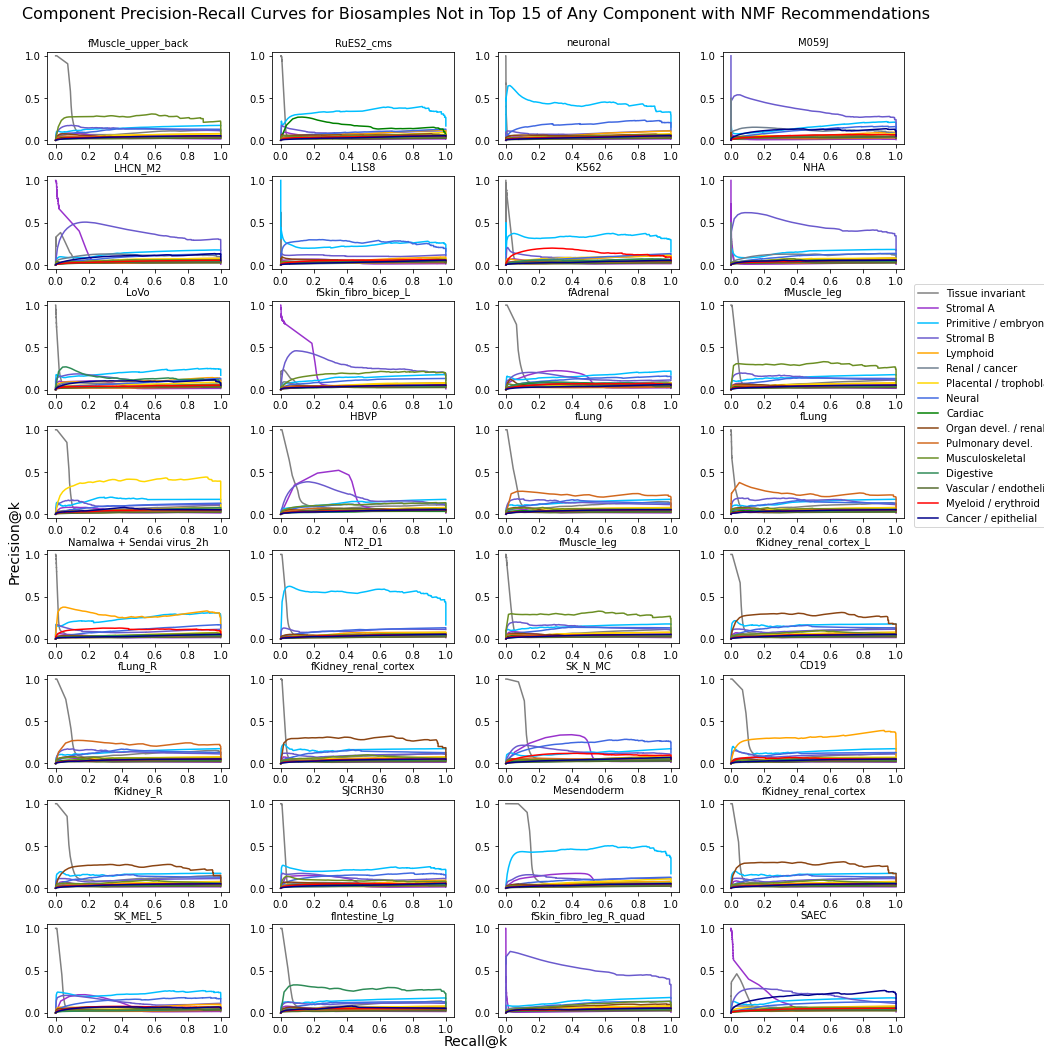

In [52]:
fig, axes = plt.subplots(nrows=8, ncols=4, figsize=(14,14))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes, range(32)):
    for i in range(len(comps)):
        ax.plot(not_top_biosample_recall[ind][i], not_top_biosample_precision[ind][i], color=color[i])
    ax.set_title(random_not_top_biosample_names[ind], fontsize=10)


fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()
fig.legend(comps, loc = (0.875, 0.5))
# print(lines)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Recall@k', ha='center', fontsize=14)
fig.text(0, 0.5, 'Precision@k', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Component Precision-Recall Curves for Biosamples Not in Top 15 of Any Component with NMF Recommendations', fontsize=16, x=0.465, y=1.03)

Text(0.465, 1.03, 'Component PR Curve AUC Values for Biosamples Not in Top 15 of Any Component with NMF Recommendations')

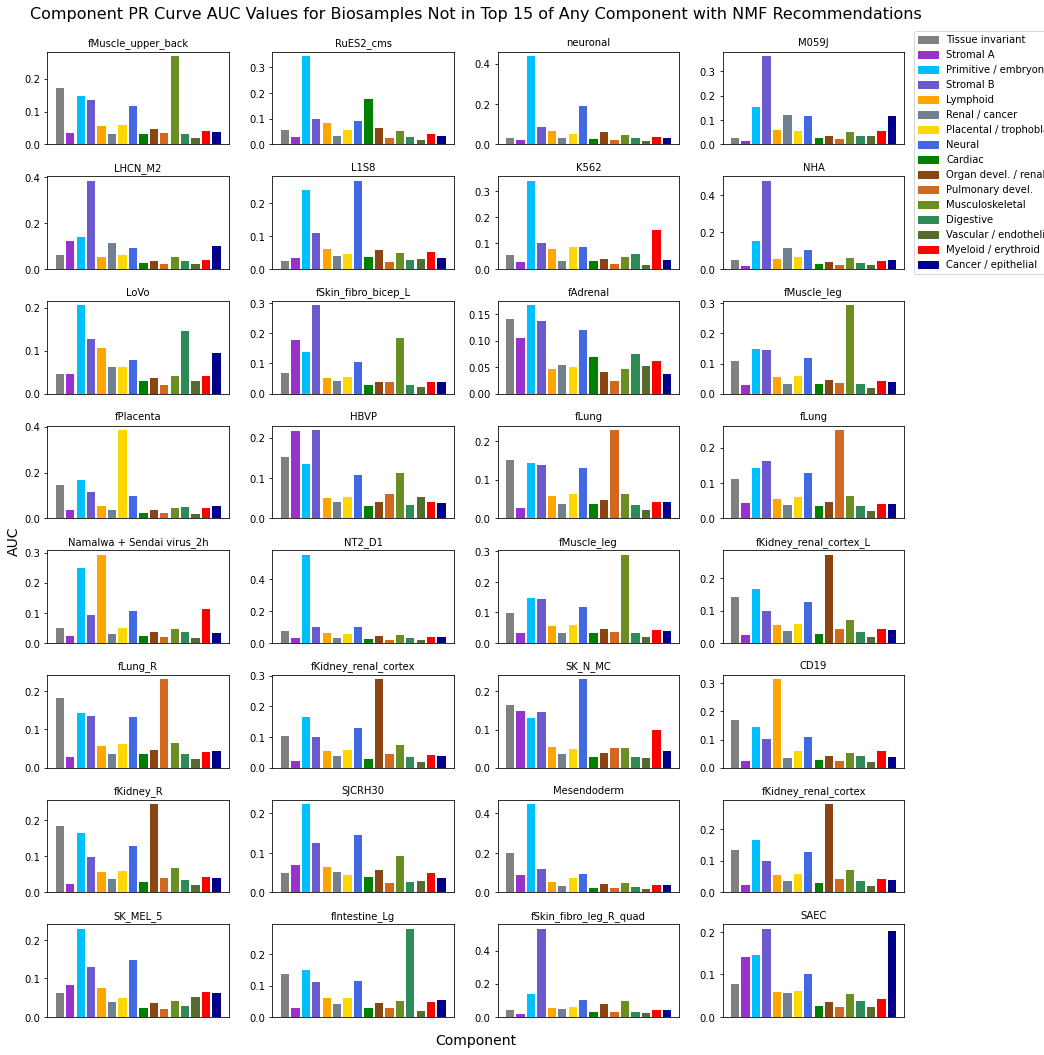

In [53]:
fig, axes = plt.subplots(nrows=8, ncols=4, figsize=(14,14))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes, range(32)):
#     for i in range(len(comps)):
#         ax.plot(top_biosample_recall[ind][i], top_biosample_precision[ind][i], color=color[i])
    ax.bar(comps, total_not_top_auc[ind], color=color)
    ax.set_title(random_not_top_biosample_names[ind], fontsize=10)
    ax.set_xticks([])
    
fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()

handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, comps, loc = (0.875, 0.74))
fig.text(0.465, 0, 'Component', ha='center', fontsize=14)
fig.text(0, 0.5, 'AUC', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Component PR Curve AUC Values for Biosamples Not in Top 15 of Any Component with NMF Recommendations', fontsize=16, x=0.465, y=1.03)

In [ ]:
pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_not_top_biosamples_each_comp_precision.pickle', 'wb')
pickle.dump(not_top_biosample_precision, pickle_out)
pickle_out.close()